<h1 style="color: #FF5733;">Pandas</h1>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Pandas -> Used for Data Manupulation and Data Analysis
# It provides two main data structures:
# Series -> One Dimensional Array
# DataFrame -> Two Dimensional Array

# Series

## Series From Lists

In [7]:
# String ~ (Object)
country = ['India', 'USA', 'Canada', 'Australia', 'Russia']
pd.Series(country)

0        India
1          USA
2       Canada
3    Australia
4       Russia
dtype: object

In [8]:
# Integers
runs = [100, 200, 300, 400, 500]
pd.Series(runs)

0    100
1    200
2    300
3    400
4    500
dtype: int64

In [9]:
# Custom Index
marks = [100, 200, 300, 400, 500]
students = ['A', 'B', 'C', 'D', 'E']
pd.Series(marks, index=students)

A    100
B    200
C    300
D    400
E    500
dtype: int64

In [12]:
# Settings a name
marks = pd.Series(marks, index=students, name='Marks')
marks

A    100
B    200
C    300
D    400
E    500
Name: Marks, dtype: int64

## Series From Dict

In [17]:
marks = {
    'A': 100,
    'B': 200,
    'C': 300,
    'D': 400,
    'E': 500
}
marks_series = pd.Series(marks, name='Marks')
marks_series

A    100
B    200
C    300
D    400
E    500
Name: Marks, dtype: int64

## Series Attributes

In [18]:
# Size
marks_series.size

5

In [19]:
# dtype
marks_series.dtype

dtype('int64')

In [20]:
# name
marks_series.name

'Marks'

In [28]:
# is_unique
print(marks_series.is_unique)
pd.Series([1, 1, 2, 3, 4, 5]).is_unique

True


False

In [ ]:
# Index
marks_series.index

Index(['A', 'B', 'C', 'D', 'E'], dtype='object')

In [32]:
# Values
marks_series.values

array([100, 200, 300, 400, 500], dtype=int64)

<h1 style="color: #FFC0CB;">Series Using read_csv</h1>

In [19]:
# With 1 column (Will not work with multiple columns 2+)

# Reading exel file instead of CSV for convenience
df = pd.read_excel('Pandas_learn.xlsx', engine='openpyxl')

# File Is Always Read As DataFrame -> Converting into Series using squeeze()

# Squeeze the DataFrame to a Series if possible
series = df.squeeze()
print(series)

0    975
1    984
2    165
3    615
4    165
5    852
Name: Subscriber Gained, dtype: int64


In [60]:
# With 2 columns

# Convert one column to index, then convert to Series

abc = pd.read_csv('D:\Machine Learning Notes\Pandas\B_energy_data.csv.csv', index_col=0) 
series = abc.squeeze()
print(series)

Outdoor Temperature (°C)
22.8    11822
33.6    10992
18.6     7999
22.8    11822
32.1    13857
15.8     6478
22.8     8815
20.2    14896
Name: Building Area (sq ft), dtype: int64


## Series Methods

In [52]:
# Head and Tail

abc = pd.read_csv('D:\Machine Learning Notes\Pandas\B_energy_data.csv.csv')
abc.head()

,Outdoor Temperature (°C),Building Area (sq ft)
0,22.8,11822
1,33.6,10992
2,18.6,7999
3,22.8,11822
4,32.1,13857


In [53]:
abc.tail(3)

,Outdoor Temperature (°C),Building Area (sq ft)
5,15.8,6478
6,22.8,8815
7,20.2,14896


In [54]:
# Sample(Random)
abc.sample(3)

,Outdoor Temperature (°C),Building Area (sq ft)
7,20.2,14896
3,22.8,11822
4,32.1,13857


In [55]:
# value_counts() -> Returns the count of unique values
abc.value_counts()

Outdoor Temperature (°C)  Building Area (sq ft)
22.8                      11822                    2
15.8                      6478                     1
18.6                      7999                     1
20.2                      14896                    1
22.8                      8815                     1
32.1                      13857                    1
33.6                      10992                    1
Name: count, dtype: int64

In [ ]:
# Sort values (It's Not Permanent)
# Sort values by a specific column 
sorted_abc = abc.sort_values(by='Building Area (sq ft)', ascending=True) # False -> descending
print(sorted_abc)

                          Building Area (sq ft)
Outdoor Temperature (°C)                       
15.8                                       6478
18.6                                       7999
22.8                                       8815
33.6                                      10992
22.8                                      11822
22.8                                      11822
32.1                                      13857
20.2                                      14896


In [ ]:
# Get the first value after sorting
top_value = sorted_abc.head(1)
print(top_value)

                          Building Area (sq ft)
Outdoor Temperature (°C)                       
15.8                                       6478


In [ ]:
# Print only the value
top_value = sorted_abc.head(1).values[0]
print(top_value)

[6478]


In [85]:
# Sort values Parmanently
abc.sort_values(by='Building Area (sq ft)', ascending=True, inplace=True)
print(abc)

                          Building Area (sq ft)
Outdoor Temperature (°C)                       
15.8                                       6478
18.6                                       7999
22.8                                       8815
33.6                                      10992
22.8                                      11822
22.8                                      11822
32.1                                      13857
20.2                                      14896


In [87]:
# Sort index
abc.sort_index(ascending=False, inplace=True)
print(abc)

                          Building Area (sq ft)
Outdoor Temperature (°C)                       
33.6                                      10992
32.1                                      13857
22.8                                       8815
22.8                                      11822
22.8                                      11822
20.2                                      14896
18.6                                       7999
15.8                                       6478


In [88]:
abc.count()

Building Area (sq ft)    8
dtype: int64

In [89]:
abc.sum()

Building Area (sq ft)    86681
dtype: int64

In [90]:
abc.product()

Building Area (sq ft)    790216110458591232
dtype: int64

In [91]:
abc.mean()

Building Area (sq ft)    10835.125
dtype: float64

In [92]:
abc.median()

Building Area (sq ft)    11407.0
dtype: float64

In [93]:
abc.mode()

,Building Area (sq ft)
0,11822


In [94]:
abc.describe()

,Building Area (sq ft)
count,8.000000
mean,10835.125000
std,2895.906887
min,6478.000000
25%,8611.000000
50%,11407.000000
75%,12330.750000
max,14896.000000


In [95]:
abc.var()

Building Area (sq ft)    8.386277e+06
dtype: float64

## Series Indexing (Slicing)

In [116]:
# Integer as Index
x = pd.Series([10, 20, 30, 40, 50], index=[1, 2, 3, 4, 5])
print(x)

1    10
2    20
3    30
4    40
5    50
dtype: int64


In [117]:
# Integer Indexing
print(x[1])

10


In [118]:
# Negative Indexing -----> Does not work here.
# print(x[-1]) -> KeyError: -1 

In [111]:
# String as Indexing
x = pd.Series([10, 20, 30, 40, 50], index=['A', 'B', 'C', 'D', 'E'])
print(x)

A    10
B    20
C    30
D    40
E    50
dtype: int64


In [112]:
# It corrently works with string index
print(x['A'])
print(x[1])
print(x[-2])

10
20
40


C:\Users\piyus\AppData\Local\Temp\ipykernel_16632\510577160.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(x[1])
C:\Users\piyus\AppData\Local\Temp\ipykernel_16632\510577160.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(x[-2])


In [113]:
# Slicing
print(x['A':'C'])

A    10
B    20
C    30
dtype: int64


In [114]:
# Negative Slicing 
print(x[-3:])

C    30
D    40
E    50
dtype: int64


In [115]:
print(x[: : 2])

A    10
C    30
E    50
dtype: int64


In [116]:
# Fancy Indexing 
print(x[['A', 'C', 'E']])
print(x[[0, 2, 4]])

A    10
C    30
E    50
dtype: int64
A    10
C    30
E    50
dtype: int64


C:\Users\piyus\AppData\Local\Temp\ipykernel_16632\2859750746.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(x[[0, 2, 4]])


## Editing Series

In [117]:
x

A    10
B    20
C    30
D    40
E    50
dtype: int64

In [118]:
# Using Indexing
x['A'] = 100
x

A    100
B     20
C     30
D     40
E     50
dtype: int64

In [119]:
# What if an index does not exist
x['F'] = 200
x

A    100
B     20
C     30
D     40
E     50
F    200
dtype: int64

In [120]:
# Slicing
x['A':'C'] = 300
x

A    300
B    300
C    300
D     40
E     50
F    200
dtype: int64

In [121]:
# Fancy Indexing
x[['A', 'C', 'E']] = [400, 400, 40000]
x

A      400
B      300
C      400
D       40
E    40000
F      200
dtype: int64

## Series With Python Functionalities

In [27]:
ABC = pd.Series([1, 2, 3, 4, 5], index=['A', 'B', 'C', 'D', 'E'])

In [13]:
# len/type/dir/sorted/max/min
print(len(ABC))
print(type(ABC))
print(dir(ABC))  # -> all the methods that can be used with the object
print(sorted(ABC))
print(max(ABC))
print(min(ABC))

5
<class 'pandas.core.series.Series'>
['A', 'B', 'C', 'D', 'E', 'T', '_AXIS_LEN', '_AXIS_ORDERS', '_AXIS_TO_AXIS_NUMBER', '_HANDLED_TYPES', '__abs__', '__add__', '__and__', '__annotations__', '__array__', '__array_priority__', '__array_ufunc__', '__bool__', '__class__', '__column_consortium_standard__', '__contains__', '__copy__', '__deepcopy__', '__delattr__', '__delitem__', '__dict__', '__dir__', '__divmod__', '__doc__', '__eq__', '__finalize__', '__float__', '__floordiv__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__iadd__', '__iand__', '__ifloordiv__', '__imod__', '__imul__', '__init__', '__init_subclass__', '__int__', '__invert__', '__ior__', '__ipow__', '__isub__', '__iter__', '__itruediv__', '__ixor__', '__le__', '__len__', '__lt__', '__matmul__', '__mod__', '__module__', '__mul__', '__ne__', '__neg__', '__new__', '__nonzero__', '__or__', '__pandas_priority__', '__pos__', '__pow__', '__radd__', '__rand__', '

In [16]:
# type conversion
print(list(ABC))
print(dict(ABC))
print(set(ABC))

[1, 2, 3, 4, 5]
{'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5}
{1, 2, 3, 4, 5}


In [30]:
# membership operator - (Check if a Index is present in the object)
print('B' in ABC)
# membership operator - (Check if a Index is present in the object)
print(2 in ABC.values)

True
True


In [34]:
# looping - Runs on values
for i in ABC:
    print(i)

print()

# looping - To Run on Index    
for i in ABC.index:
    print(i)

1
2
3
4
5

A
B
C
D
E


In [36]:
# Arithmetic Operators (Broadcasting)
ABC + 10

A    11
B    12
C    13
D    14
E    15
dtype: int64

In [37]:
# Relational Operators
ABC > 3

A    False
B    False
C    False
D     True
E     True
dtype: bool

## Boolean Indexing On Series

In [40]:
# Find no of 50's and 100's in the series
ABC = pd.Series([10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
print(ABC[ABC >= 50].count())

6


In [42]:
# Count no of day when I had more than 200 subs a day
subs = pd.Series([100, 150, 200, 250, 300, 350, 400, 450, 500])
print(subs[subs > 200].size)

6


In [53]:
# Find actors with more than 20 movies (list of actor with movies)
movies = pd.Series([10, 20, 30, 40, 50, 10], index=['A', 'B', 'C', 'D', 'E', 'F'])
num_movies = movies.value_counts()
print(num_movies) 
print(num_movies >= 2)
print(num_movies[num_movies >= 2])

10    2
20    1
30    1
40    1
50    1
Name: count, dtype: int64
10     True
20    False
30    False
40    False
50    False
Name: count, dtype: bool
10    2
Name: count, dtype: int64


## Plotting Graph On Series

<Axes: >

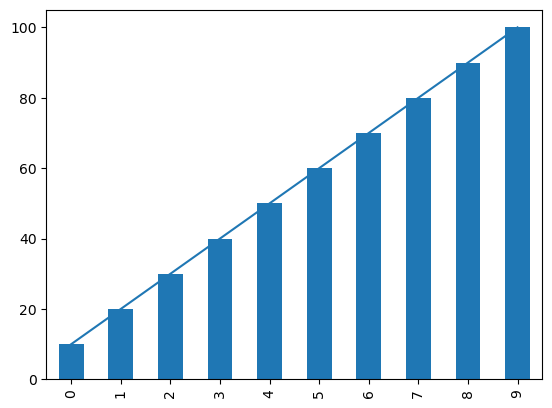

In [58]:
ABC.plot()
ABC.plot(kind='bar')

<Axes: >

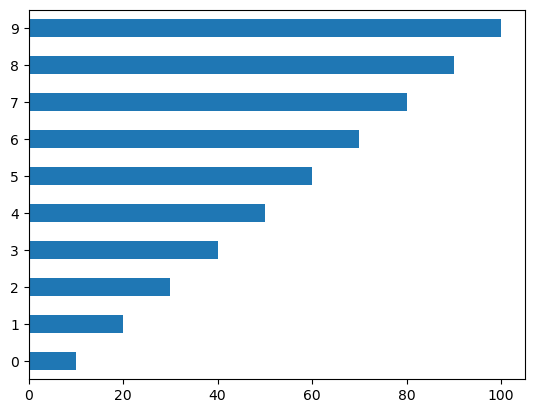

In [59]:
ABC.plot(kind='barh')

<Axes: >

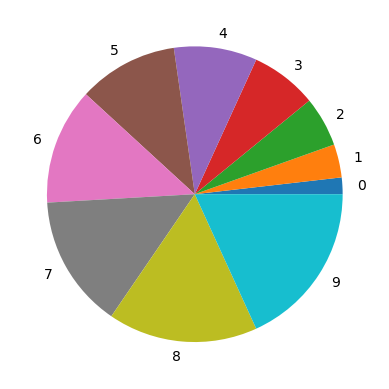

In [60]:
ABC.plot(kind='pie')

<Axes: >

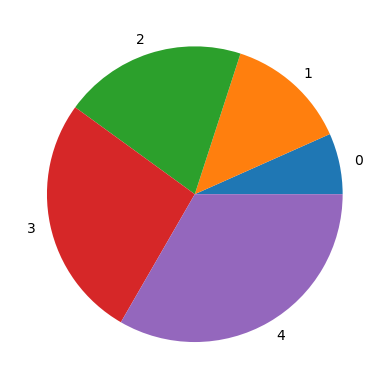

In [61]:
ABC.head(5).plot(kind='pie')

## Some Important Series Method

In [72]:
# astype
import sys
print(sys.getsizeof(ABC))
print(sys.getsizeof(ABC.astype('int8')))
print(sys.getsizeof(ABC.astype('int16')))

244
174
184


In [73]:
# between
print(ABC[ABC.between(20, 50)])

1    20
2    30
3    40
4    50
dtype: int64


In [74]:
# clip
ABC.clip(40, 50)

0    40
1    40
2    40
3    40
4    50
5    50
6    50
7    50
8    50
9    50
dtype: int64

In [80]:
# drop_duplicates (default keep='first')
print(ABC.drop_duplicates(keep='last'))
# For Checking if there are duplicates
print(ABC.duplicated().sum())

0     10
1     20
2     30
3     40
4     50
5     60
6     70
7     80
8     90
9    100
dtype: int64
0


In [87]:
# isnull
ABC = pd.Series([10, 20, 30, 40, 50, np.nan, 70, 80, 90, np.nan])
print(ABC.size)
print(ABC.count())
print(ABC.isnull().sum())

10
8
2


In [85]:
# dropna
print(ABC.dropna())

0    10.0
1    20.0
2    30.0
3    40.0
4    50.0
6    70.0
7    80.0
8    90.0
dtype: float64


In [89]:
# fillna
print(ABC.fillna(0))

0    10.0
1    20.0
2    30.0
3    40.0
4    50.0
5     0.0
6    70.0
7    80.0
8    90.0
9     0.0
dtype: float64


In [95]:
# isin

print(ABC[(ABC == 50) | (ABC == 70)])
# Better for Multiple Values
ABC[ABC.isin([50, 70])]


4    50.0
6    70.0
dtype: float64


4    50.0
6    70.0
dtype: float64

In [103]:
# apply (convert the float values to strings before applying the split() method.)

# ABC.apply(lambda x: x.split()[0].upper())
print(ABC.apply(lambda x: str(int(x)).split()[0].upper()if not pd.isnull(x) else x))

print(ABC.apply(lambda x: 'Good' if x > ABC.mean() else 'Bad'))

0     10
1     20
2     30
3     40
4     50
5    NaN
6     70
7     80
8     90
9    NaN
dtype: object
0     Bad
1     Bad
2     Bad
3     Bad
4    Good
5     Bad
6    Good
7    Good
8    Good
9     Bad
dtype: object


# Copy And Views

In [108]:
# head() and tail() gives the view of data not copy
# Any change in this changes the original

# copy (No change in original)
new = ABC.head().copy()
new[0] = 100
print(new)

0    100.0
1     20.0
2     30.0
3     40.0
4     50.0
dtype: float64


<h1 style="color:Purple;">DataFrame</h1>


In [122]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Creating DataFrame

In [123]:
# using lists (2D)
student_data = [
    ['A', 10, 20, 30],
    ['B', 20, 30, 40],
    ['C', 30, 40, 50],
    ['D', 40, 50, 60],
    ['E', 50, 60, 70]
]
pd.DataFrame(student_data, columns = ['Name', 'Maths', 'Physics', 'Chemistry'])

,Name,Maths,Physics,Chemistry
0,A,10,20,30
1,B,20,30,40
2,C,30,40,50
3,D,40,50,60
4,E,50,60,70


In [168]:
# using dicts
student_data = {
    'Name': ['A', 'B', 'C', 'D', 'E'],
    'Maths': [10, 20, 30, 40, 50],
    'Physics': [20, 30, 40, 50, 60],
    'Chemistry': [30, 40, 50, 60, 70]
}
stud = pd.DataFrame(student_data)
stud

,Name,Maths,Physics,Chemistry
0,A,10,20,30
1,B,20,30,40
2,C,30,40,50
3,D,40,50,60
4,E,50,60,70


In [129]:
# using read_csv
students = pd.read_csv('D:\Machine Learning Notes\Pandas\B_energy_data.csv.csv')
students

,Outdoor Temperature (°C),Building Area (sq ft)
0,22.8,11822
1,33.6,10992
2,18.6,7999
3,22.8,11822
4,32.1,13857
5,15.8,6478
6,22.8,8815
7,20.2,14896


## DataFrame Attributes And Methods

In [130]:
# shape
students.shape

(8, 2)

In [131]:
# dtypes
students.dtypes

Outdoor Temperature (°C)    float64
Building Area (sq ft)         int64
dtype: object

In [132]:
# index
students.index

RangeIndex(start=0, stop=8, step=1)

In [133]:
# columns
students.columns

Index(['Outdoor Temperature (°C)', 'Building Area (sq ft)'], dtype='object')

In [134]:
# values
students.values

array([[   22.8, 11822. ],
       [   33.6, 10992. ],
       [   18.6,  7999. ],
       [   22.8, 11822. ],
       [   32.1, 13857. ],
       [   15.8,  6478. ],
       [   22.8,  8815. ],
       [   20.2, 14896. ]])

In [137]:
# head and tail
print(students.head(2))
students.tail(2)

   Outdoor Temperature (°C)  Building Area (sq ft)
0                      22.8                  11822
1                      33.6                  10992


,Outdoor Temperature (°C),Building Area (sq ft)
6,22.8,8815
7,20.2,14896


In [ ]:
# sample 
students.sample(2)

,Outdoor Temperature (°C),Building Area (sq ft)
2,18.6,7999
4,32.1,13857


In [143]:
# info
students.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 2 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Outdoor Temperature (°C)  8 non-null      float64
 1   Building Area (sq ft)     8 non-null      int64  
dtypes: float64(1), int64(1)
memory usage: 260.0 bytes


In [144]:
# describe
students.describe()

,Outdoor Temperature (°C),Building Area (sq ft)
count,8.000000,8.000000
mean,23.587500,10835.125000
std,6.228606,2895.906887
min,15.800000,6478.000000
25%,19.800000,8611.000000
50%,22.800000,11407.000000
75%,25.125000,12330.750000
max,33.600000,14896.000000


In [149]:
# isnull
students.isnull().sum()

Outdoor Temperature (°C)    0
Building Area (sq ft)       0
dtype: int64

In [150]:
# duplicated
students.duplicated() # .sum() -> 1

0    False
1    False
2    False
3     True
4    False
5    False
6    False
7    False
dtype: bool

In [151]:
# rename
students.rename(columns = {'Building Area (sq ft)': 'Area'}, inplace=True)
students

,Outdoor Temperature (°C),Area
0,22.8,11822
1,33.6,10992
2,18.6,7999
3,22.8,11822
4,32.1,13857
5,15.8,6478
6,22.8,8815
7,20.2,14896


## Math Methods

In [ ]:
# sum
# axis 0 -> column wise (default)
# axis 1 -> row wise
students.sum(axis=0)


Outdoor Temperature (°C)      188.7
Area                        86681.0
dtype: float64

In [159]:
# mean
students.mean(axis=1)

0    5922.40
1    5512.80
2    4008.80
3    5922.40
4    6944.55
5    3246.90
6    4418.90
7    7458.10
dtype: float64

In [161]:
# min
students.min()

Outdoor Temperature (°C)      15.8
Area                        6478.0
dtype: float64

## Selecting Columns from DataFrame

In [165]:
# single column
print(students['Area'])
type(students['Area'])

0    11822
1    10992
2     7999
3    11822
4    13857
5     6478
6     8815
7    14896
Name: Area, dtype: int64


pandas.core.series.Series

In [167]:
# multi column
print(students[['Area', 'Outdoor Temperature (°C)']])

    Area  Outdoor Temperature (°C)
0  11822                      22.8
1  10992                      33.6
2   7999                      18.6
3  11822                      22.8
4  13857                      32.1
5   6478                      15.8
6   8815                      22.8
7  14896                      20.2


## Selecting Rows from DataFrame

In [170]:
# using dicts
student_data = {
    'Name': ['A', 'B', 'C', 'D', 'E'],
    'Maths': [10, 20, 30, 40, 50],
    'Physics': [20, 30, 40, 50, 60],
    'Chemistry': [30, 40, 50, 60, 70]
}
stud = pd.DataFrame(student_data)
stud.set_index('Name', inplace=True)
stud

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40
C,30,40,50
D,40,50,60
E,50,60,70


     -> iloc : searches using index position
     -> loc : search using index lables

In [174]:
# single row
print(students.iloc[0])

Outdoor Temperature (°C)       22.8
Area                        11822.0
Name: 0, dtype: float64


In [ ]:
# multiple rows
print(students.iloc[0:3])
print(students.iloc[[0, 2, 4]]) # Fancy Indexing

   Outdoor Temperature (°C)   Area
0                      22.8  11822
1                      33.6  10992
2                      18.6   7999
   Outdoor Temperature (°C)   Area
0                      22.8  11822
2                      18.6   7999
4                      32.1  13857


In [177]:
stud.loc['B']

Maths        20
Physics      30
Chemistry    40
Name: B, dtype: int64

In [179]:
# Range in iloc does not include last 
# Range in loc includes last
stud.loc['A':'C']

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40
C,30,40,50


In [181]:
# Can Also use iloc
stud.iloc[0:3]

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40
C,30,40,50


## Selecting Both Rows and Column

In [ ]:
## First 3 Column & 2 Rows
stud.iloc[0:2, 0:3]

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40


In [183]:
stud.loc['A':'C', 'Maths':'Physics']

,Maths,Physics
Name,,
A,10,20
B,20,30
C,30,40


## Filtering a DataFrame

In [188]:
# Printing Physics Marks for those who got 20 in Maths
new = stud['Maths'] == 20
new_st = stud[new]
new_st['Physics'] 


Name
B    30
Name: Physics, dtype: int64

In [189]:
# Same thing in one line
stud[stud['Maths'] == 20]['Physics']

Name
B    30
Name: Physics, dtype: int64

In [195]:
# shape[0] -> row
stud[stud['Maths'] == 20].shape[0]


1

In [203]:
# either maths 20 or physics 20
# Working with Binary
stud[(stud['Maths'] == 20) ^ (stud['Physics'] == 20)]

,Maths,Physics,Chemistry
Name,,,
A,10,20,30
B,20,30,40


In [216]:
# Percentage that if got math >= 20 then physics >= 20
# Normally if one condition use == 
# if 2 conditions use &
(stud[(stud['Maths'] >= 20) == (stud['Physics'] >= 20)].shape[0]/stud.shape[0])*100

80.0

In [217]:
# Action movies with rating higher than 7.5
movies = {
    'Name': ['A', 'B', 'C', 'D', 'E'],
    'Genre': ['Action/Comedy', 'Comedy', 'Horror/Action', 'Action', 'Comedy'],
    'Rating': [7.5, 8, 6, 8.5, 7]
}
movies = pd.DataFrame(movies)
movies

,Name,Genre,Rating
0,A,Action/Comedy,7.5
1,B,Comedy,8.0
2,C,Horror/Action,6.0
3,D,Action,8.5
4,E,Comedy,7.0


In [232]:
# Multiple Genre-> Can't Select Action alone
# Converting into string and splitting
cond1 = movies['Genre'].str.split('/').apply(lambda x: 'Action' in x)
cond1
# OR
# cond1 = movies['Genre'].str.contains('Action')

0     True
1    False
2     True
3     True
4    False
Name: Genre, dtype: bool

In [230]:
cond2 = movies['Rating'] >= 7.5
cond2

0     True
1     True
2    False
3     True
4    False
Name: Rating, dtype: bool

In [231]:
movies[cond1 & cond2]

,Name,Genre,Rating
0,A,Action/Comedy,7.5
3,D,Action,8.5


## Adding New Cols

In [234]:
# New Cols
movies['Country'] = ['USA', 'India', 'China', 'Russia', 'Japan']
movies

,Name,Genre,Rating,Country
0,A,Action/Comedy,7.5,USA
1,B,Comedy,8.0,India
2,C,Horror/Action,6.0,China
3,D,Action,8.5,Russia
4,E,Comedy,7.0,Japan


In [237]:
# 1st Gerene
movies['Genre'].str.split('/').str[0]
# Or
# movies['Genre'].str.split('/').apply(lambda x: x[0])

0    Action
1    Comedy
2    Horror
3    Action
4    Comedy
Name: Genre, dtype: object

## Important DataFrame Functions

In [249]:
# astype
movies.info()
print()
movies['Rating'] = movies['Rating'].astype('int32')
movies.info()
# Object -> Category (if it is a category)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Name     5 non-null      object
 1   Genre    5 non-null      object
 2   Rating   5 non-null      int64 
 3   Country  5 non-null      object
dtypes: int64(1), object(3)
memory usage: 292.0+ bytes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Name     5 non-null      object
 1   Genre    5 non-null      object
 2   Rating   5 non-null      int32 
 3   Country  5 non-null      object
dtypes: int32(1), object(3)
memory usage: 272.0+ bytes


In [239]:
# value_counts

In [238]:
# sort_values --> ascending --> na_position --> inplace --> multiple_cols

<h3 style="color: Pink;">Group By</h3>